# Imports and load data

## Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cmcrameri import cm
import os
import socket
# ------------------------------------------------------------
# Load mean IWC profile data
# ------------------------------------------------------------


## Load data (Only bulk_data_df important)

In [2]:
if socket.gethostname()=='iacmac-ds4990':
    BULK_PATH = "/Volumes/University_stuff/Code_Projects/MSGI/Bulk_data"
else:
    BULK_PATH = "/nfs/ch4/wolke_scratch/dnikolo/GTE_Validation/DARDAR/Bulk/Bulk_statistics"
# bulk_data_df = pd.read_parquet(os.path.join(BULK_PATH,"glaciations_with_bulk_data_V3_1_2007.parquet"))
# iwc_rel_df_1 = pd.read_parquet(os.path.join(BULK_PATH,"iwc_rel_df_V3_1_2007.parquet"))
# iwc_rel_df_2 = pd.read_parquet(os.path.join(BULK_PATH,"iwc_rel_df_V3_1_2008.parquet"))
# mean_iwc_by_height_df = pd.read_parquet(os.path.join(BULK_PATH,"mean_iwc_by_height_data_V3_1_2007.parquet"))
# iwc_rel_df_loaded = pd.concat([iwc_rel_df_1, iwc_rel_df_2], ignore_index=True)

bulk_data_df_1 = pd.read_parquet(os.path.join(BULK_PATH,"glaciations_with_bulk_data_V3_1_2007.parquet"))
bulk_data_df_2 = pd.read_parquet(os.path.join(BULK_PATH,"glaciations_with_bulk_data_V3_1_2008.parquet"))
bulk_data_df = pd.concat([bulk_data_df_1, bulk_data_df_2], ignore_index=True)

In [3]:
bulk_data_df.iloc[0]["Z_bulk_means"][0]

array([3.2381746e-03, 4.6950034e-03, 5.4478566e-03, 5.5642747e-03,
       5.1425821e-03, 4.8362492e-03, 4.6554161e-03, 5.3024124e-03,
       6.5835328e-03, 8.0642626e-03, 7.8764418e-03, 1.5979230e+01,
       4.7678688e+01, 1.3856523e+02, 4.7321710e+02, 4.4885435e+03,
       1.3954935e+04, 2.7261051e+04], dtype=float32)

Filter rows with no measurements (Cehck why are there such???)

In [4]:
bulk_data_df=bulk_data_df[bulk_data_df.apply(lambda row: not (len(row["bulk_height_means_m"])==0) , axis=1)]

## Split cells by pass

In [5]:
ROWS_1D=["ddc_cloud_top_temp_means_K","ddc_cloud_top_height_means_m", "iwc_top_means", "colocation_time"]

In [6]:
import numpy as np
import pandas as pd


def is_pass_list(x):
    """
    True if x looks like a per-pass list/array:
    e.g. [pass1, pass2] where each pass may itself be a list/array.
    """
    if isinstance(x, np.ndarray):
        return isinstance(x[0], np.ndarray)

    return False


def split_rows_by_pass(df, reference_col="bulk_height_means_m"):
    new_rows = []

    for _, row in df.iterrows():
        ref_val = row[reference_col]

        # Number of passes, e.g. len([[...], [...]]) == 2
        if is_pass_list(ref_val):
            n_passes = len(ref_val)
        else:
            n_passes = 1
        for pass_i in range(n_passes):
            new_row = {}

            for col in df.columns:
                val = row[col]
                # If this column contains per-pass values, take the matching pass
                if is_pass_list(val):
                    if pass_i < len(val):
                        new_row[col] = val[pass_i]
                    else:
                        # Leave empty if this column does not have this pass
                        new_row[col] = np.nan
                elif col in ROWS_1D:
                    new_row[col] = val[pass_i]
                else:
                    # Scalar / non-list values are copied to every split row
                    new_row[col] = val
                


            new_rows.append(new_row)

    return pd.DataFrame(new_rows, columns=df.columns)

# row = 

bulk_data_df_split = split_rows_by_pass(
    bulk_data_df,
    reference_col="bulk_height_means_m"
)
bulk_data_df_split

,Cloud_ID,Time [m],Magnitude,Glac_start_ind,Glac_peak_ind,Linear,line_rmse,Rate_arr,Mean_glac_rate,Glaciation time [h],...,iwc_top_means,bulk_height_means_m,ddc_cloud_top_height_means_m,ddc_cloud_top_temp_means_K,ext_bulk_means,temp_bulk_means,Z_bulk_means,bulk_level_offset_top_m,bulk_level_offset_bottom_m,bulk_level_offset_mid_m
0,70032,75,0.716289,46,51,True,0.090226,"[0.5730308055877685, 0.5730308055877685, 0.573...",0.573031,1.25,...,0.000002,"[6.012133, 6.208238, 6.084497, 5.9561296, 5.90...",6.012133,240.739761,"[2.9812034e-05, 3.1037875e-05, 3.058996e-05, 2...","[240.73976, 239.70326, 240.6571, 241.54845, 24...","[0.0032381746, 0.0046950034, 0.0054478566, 0.0...","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0..."
1,72095,30,0.564687,32,34,False,0.113881,"[1.8503361540113865, 1.246587775444679, 0.1739...",1.090303,0.50,...,0.000054,"[4.4200945, 4.300247, 4.180037, 4.06028, 3.940...",4.420094,258.236023,"[0.002440295, 0.0038495741, 0.0048959274, 0.00...","[258.23602, 258.8475, 259.37033, 259.84387, 26...","[0.06958358, 0.1391759, 0.23620418, 0.36153236...","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0..."
2,73526,15,0.434614,20,21,True,0.000000,[1.7384560108184814],1.738456,0.25,...,0.000001,"[3.1008463, 2.928, 2.8091538, 2.4287832, 2.317...",3.100846,256.385834,"[9.647788e-06, 1.5636453e-05, 2.3636223e-05, 3...","[256.38583, 257.47296, 258.06116, 259.5602, 25...","[0.002137324, 0.0048362347, 0.008402162, 0.012...","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0..."
3,73526,15,0.434614,20,21,True,0.000000,[1.7384560108184814],1.738456,0.25,...,0.000184,"[2.8605168, 2.54741, 2.2648573, 2.1440778, 2.1...",2.860517,257.866089,"[0.0013777114, 0.00071305217, 0.00041304433, 0...","[257.8661, 259.55402, 260.86667, 261.39035, 26...","[0.0031650555, 0.0054872693, 0.008136633, 0.01...","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0..."
4,74600,75,1.000000,20,25,False,0.147536,"[0.7355483057504995, 1.2362305155394049, 1.236...",0.813812,1.25,...,0.000019,"[6.575131, 6.505823, 6.3253098, 6.209402, 6.08...",6.575131,256.105347,"[0.00054223614, 0.0006568758, 0.00075381395, 0...","[256.10535, 256.72083, 257.95056, 258.69864, 2...","[0.092649944, 0.17385349, 0.23061784, 0.296942...","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3359,3681457,1170,0.732136,27,105,False,0.217861,"[0.02125418956784396, 0.06910958712063696, 0.1...",0.110727,19.50,...,0.000003,"[4.4516244, 4.2864814, 4.0873322, 3.9671848, 3...",4.451624,243.201080,"[7.1099734e-05, 8.962477e-05, 0.00011307858, 0...","[243.20108, 244.31627, 245.61755, 246.3929, 24...","[0.0053640106, 0.009900559, 0.015516799, 0.021...","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0..."
3360,3681457,1170,0.732136,27,105,False,0.217861,"[0.02125418956784396, 0.06910958712063696, 0.1...",0.110727,19.50,...,0.000005,"[4.6939387, 4.602554, 4.493422, 4.3605795, 4.2...",4.693939,242.173737,"[0.00011999376, 0.00017414901, 0.00023670889, ...","[242.17374, 242.84634, 243.82594, 245.1301, 24...","[0.027026812, 0.05622481, 0.09936894, 0.141066...","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0..."
3361,3681665,285,0.898702,59,78,False,0.329054,"[0.16659572034164452, 0.17573920219729536, 0.1...",

In [7]:
test_row=bulk_data_df_split.iloc[0]

## Stats by relative time

In [8]:
ORIGINAL_VALID_CLOUD_COLUMNS = bulk_data_df.columns.tolist()

bulk_data_df_split["rel_ind"] = bulk_data_df_split.apply(
    lambda row: int(round(
        (pd.Timestamp(row["colocation_time"]) - row["track_start_time"]) / pd.Timedelta(minutes=15)
    )) - int(row["Glac_peak_ind"]),
    axis=1
)
bulk_data_df_split["rel_time_min"] = bulk_data_df_split["rel_ind"]*15
sample = bulk_data_df_split.sample(100, random_state=1)

In [9]:
sample["bulk_level_offset_bottom_m"]

2646    [-120.0, -240.0, -360.0, -480.0, -600.0, -720....
3266    [-120.0, -240.0, -360.0, -480.0, -600.0, -720....
2367    [-120.0, -240.0, -360.0, -480.0, -600.0, -720....
761     [-120.0, -240.0, -360.0, -480.0, -600.0, -720....
2801    [-120.0, -240.0, -360.0, -480.0, -600.0, -720....
                              ...                        
600     [-120.0, -240.0, -360.0, -480.0, -600.0, -720....
3304    [-120.0, -240.0, -360.0, -480.0, -600.0, -720....
2009    [-120.0, -240.0, -360.0, -480.0, -600.0, -720....
2359    [-120.0, -240.0, -360.0, -480.0, -600.0, -720....
2173    [-120.0, -240.0, -360.0, -480.0, -600.0, -720....
Name: bulk_level_offset_bottom_m, Length: 100, dtype: object

In [10]:
MODE = "median"
if MODE == "mean":
    stats_by_rel_time = (
        bulk_data_df_split
        .groupby("rel_ind")
        .agg(
            n_hits=("iwc_bulk_means", "count"),

            mean_iwc_profile=(
                "iwc_bulk_means",
                lambda profiles: np.nanmean(np.stack(profiles), axis=0),
            ),
            mean_Z_profile=(
                "Z_bulk_means",
                lambda profiles: np.nanmean(np.stack(profiles), axis=0),
            ),
            mean_ext_profile=(
                "ext_bulk_means",
                lambda profiles: np.nanmean(np.stack(profiles), axis=0),
            ),
            mean_temp_profile=(
                "temp_bulk_means",
                lambda profiles: np.nanmean(np.stack(profiles), axis=0),
            ),

            mean_bulk_height_profile_m=(
                "bulk_level_offset_mid_m",
                lambda profiles: np.nanmean(np.stack(profiles), axis=0),
            ),

            bulk_offset_top_m=(
                "bulk_level_offset_top_m",
                lambda profiles: np.nanmean(np.stack(profiles), axis=0),
            ),

            bulk_offset_bottom_m=(
                "bulk_level_offset_bottom_m",
                lambda profiles: np.nanmean(np.stack(profiles), axis=0),
            ),

            dd_cth=(
                "ddc_cloud_top_height_means_m",
                "mean",
            ),

            sev_cth=(
                "avg_cth",
                "mean",
            ),

            dd_ctt=(
                "ddc_cloud_top_temp_means_K",
                "mean",
            ),

            mean_iwc_ct=(
                "iwc_top_means",
                "mean",
            ),

            sev_ctt=(
                "avg_ctt",
                "mean",
            ),
            
            mean_area_km=(
                "avg_size[km]",
                "mean",
            ),
            
        )
        .reset_index()
    )
elif MODE=="median":
    print("Calculating median")
    stats_by_rel_time = (
    bulk_data_df_split
    .groupby("rel_ind")
    .agg(
        n_hits=("iwc_bulk_means", "count"),

        mean_iwc_profile=(
            "iwc_bulk_means",
            lambda profiles: np.nanmedian(np.stack(profiles), axis=0),
        ),
        mean_Z_profile=(
            "Z_bulk_means",
            lambda profiles: np.nanmedian(np.stack(profiles), axis=0),
        ),
        mean_ext_profile=(
            "ext_bulk_means",
            lambda profiles: np.nanmedian(np.stack(profiles), axis=0),
        ),
        mean_temp_profile=(
            "temp_bulk_means",
            lambda profiles: np.nanmedian(np.stack(profiles), axis=0),
        ),

        mean_bulk_height_profile_m=(
            "bulk_level_offset_mid_m",
            lambda profiles: np.nanmedian(np.stack(profiles), axis=0),
        ),

        bulk_offset_top_m=(
            "bulk_level_offset_top_m",
            lambda profiles: np.nanmedian(np.stack(profiles), axis=0),
        ),

        bulk_offset_bottom_m=(
            "bulk_level_offset_bottom_m",
            lambda profiles: np.nanmedian(np.stack(profiles), axis=0),
        ),

        dd_cth=(
            "ddc_cloud_top_height_means_m",
            "median",
        ),

        sev_cth=(
            "avg_cth",
            "median",
        ),

        dd_ctt=(
            "ddc_cloud_top_temp_means_K",
            "median",
        ),

        mean_iwc_ct=(
            "iwc_top_means",
            "median",
        ),


        sev_ctt=(
            "avg_ctt",
            "median",
        ),
        
        mean_area_km=(
            "avg_size[km]",
            "median",
        ),
        
        )
        .reset_index()
    )
else:
    raise ValueError("Set statistics 'MODE' to mean or median")
stats_by_rel_time["rel_time_min"] = stats_by_rel_time["rel_ind"] * 15

Calculating median


/var/folders/ps/bdhslmwj4t16q5_v16j9hwmc0000gt/T/ipykernel_98108/3362422930.py:84: RuntimeWarning: All-NaN slice encountered
  lambda profiles: np.nanmedian(np.stack(profiles), axis=0),
/var/folders/ps/bdhslmwj4t16q5_v16j9hwmc0000gt/T/ipykernel_98108/3362422930.py:96: RuntimeWarning: All-NaN slice encountered
  lambda profiles: np.nanmedian(np.stack(profiles), axis=0),


# Optical depth statistics

In [11]:
def calculate_top_depth(row):
    tot_thickness = 0
    small_ext_counter = 0
    for j, ext in enumerate(row["ext_bulk_means"]):
        lev_depth = row.bulk_level_offset_top_m[j]-row.bulk_level_offset_bottom_m[j]
        tot_thickness += lev_depth*ext
        if ext<2.0e-4:
            small_ext_counter+=1
        if tot_thickness>=0.3:
            # print(tot_thickness,j*120,small_ext_counter*120)
            return j*120
    return None
        
            
sample["ct_depth"] = sample.apply(calculate_top_depth,axis=1)

In [12]:
(sample["ct_depth"]>600).value_counts()

ct_depth
False    69
True     31
Name: count, dtype: int64

In [13]:
def optical_depth_path(row):
    if row.bulk_level_offset_top_m is None:
        return None

    z_top = np.asarray(row.bulk_level_offset_top_m, dtype=float)
    z_bottom = np.asarray(row.bulk_level_offset_bottom_m, dtype=float)
    ext = np.asarray(row["ext_bulk_means"], dtype=float)

    dz = np.abs(z_top - z_bottom)

    # optional safety check
    if len(dz) != len(ext):
        raise ValueError(
            f"Length mismatch: dz has {len(dz)} layers, extinction has {len(ext)} values"
        )

    tau_path = [0.0]
    depth_path = [0.0]

    tau = 0.0
    depth = 0.0

    for layer_dz, layer_ext in zip(dz, ext):
        layer_tau = layer_dz * layer_ext

        tau += layer_tau
        depth += layer_dz

        tau_path.append(tau)
        depth_path.append(depth)

    return {
        "depth_m": np.asarray(depth_path),
        "tau": np.asarray(tau_path)
    }

In [14]:
# Calculate total optical depth per cloud 
bulk_data_df_split["2km_cot"] = bulk_data_df_split.apply(lambda row: optical_depth_path(row)["tau"][-1], axis=1)
bulk_data_df_split["continious_cloud"] = bulk_data_df_split.apply(lambda row: ((optical_depth_path(row)["tau"][1:]-optical_depth_path(row)["tau"][:-1])>5*1e-4).all(), axis=1)

<Figure size 700x500 with 0 Axes>

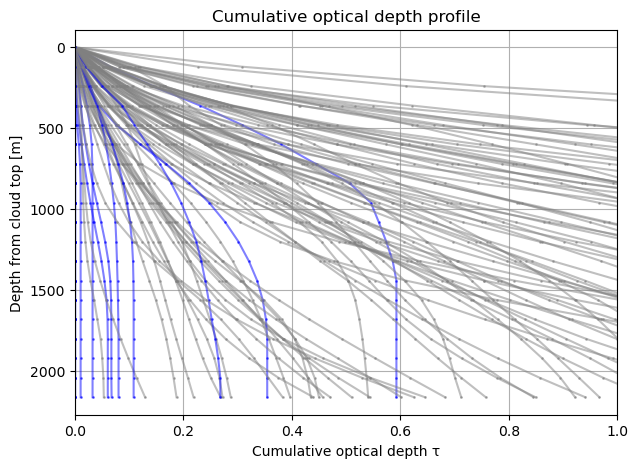

In [15]:
import numpy as np
import matplotlib.pyplot as plt

import numpy as np
import matplotlib.pyplot as plt




plt.figure(figsize=(7, 5))

plt.figure(figsize=(7, 5))

for row_idx, row in sample.iterrows():
    p = optical_depth_path(row)

    if p is None:
        continue
    if ((p["tau"][1:]-p["tau"][:-1])<5*1e-4).any():
        plt.plot(
            p["tau"],
            p["depth_m"],
            alpha=0.5,
            marker="o",
            color="blue",
            markersize=1
        )
    else:
        plt.plot(
            p["tau"],
            p["depth_m"],
            alpha=0.5,
            marker="o",
            color="gray",
            markersize=1
        )



# plt.axvline(0.2, linestyle="--", linewidth=1, label="τ = 0.2")

plt.xlabel("Cumulative optical depth τ")
plt.ylabel("Depth from cloud top [m]")
plt.title("Cumulative optical depth profile")
plt.grid(True)
plt.xlim(0, 1)

# Optional: depth increasing downward
plt.gca().invert_yaxis()

plt.show()

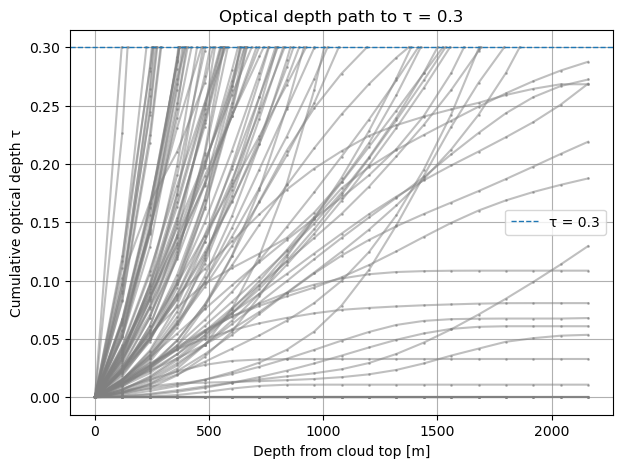

In [16]:
import numpy as np
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.pyplot as plt

def optical_depth_path_to_03(row, tau_target=0.3):
    if row.bulk_level_offset_top_m is None:
        return None

    z_top = np.asarray(row.bulk_level_offset_top_m, dtype=float)
    z_bottom = np.asarray(row.bulk_level_offset_bottom_m, dtype=float)
    ext_profile = np.asarray(row["ext_bulk_means"], dtype=float)

    dz = np.abs(z_top - z_bottom)

    if len(dz) != len(ext_profile):
        raise ValueError(
            f"Length mismatch: dz has {len(dz)} layers, "
            f"extinction has {len(ext_profile)} values"
        )

    tau = 0.0
    depth = 0.0

    depth_path = [0.0]
    tau_path = [0.0]

    for layer_dz, ext in zip(dz, ext_profile):
        layer_tau = layer_dz * ext

        # if tau_target is reached inside this layer, interpolate
        if tau + layer_tau >= tau_target:
            remaining_tau = tau_target - tau

            if ext > 0:
                depth_inside_layer = remaining_tau / ext
            else:
                depth_inside_layer = layer_dz

            depth += depth_inside_layer
            tau = tau_target

            depth_path.append(depth)
            tau_path.append(tau)
            break

        tau += layer_tau
        depth += layer_dz

        depth_path.append(depth)
        tau_path.append(tau)

    return {
        "depth_m": np.asarray(depth_path),
        "tau": np.asarray(tau_path),
        "reached_03": tau >= tau_target
    }

plt.figure(figsize=(7, 5))

for row_idx, row in sample.iterrows():
    p = optical_depth_path_to_03(row, tau_target=0.3)

    if p is None:
        continue

    plt.plot(
        p["depth_m"],
        p["tau"],
        alpha=0.5,
        marker="o",
        color="gray",
        markersize=1
    )

plt.axhline(0.3, linestyle="--", linewidth=1, label="τ = 0.3")

plt.xlabel("Depth from cloud top [m]")
plt.ylabel("Cumulative optical depth τ")
plt.title("Optical depth path to τ = 0.3")
plt.grid(True)
plt.legend()
plt.show()

# Z statistics

In [17]:
(bulk_data_df["track_length"] / pd.Timedelta(minutes=15)>bulk_data_df["Glac_peak_ind"]).value_counts(normalize=True)

True     0.807851
False    0.192149
Name: proportion, dtype: float64

In [18]:
bulk_data_df_split.keys()

Index(['Cloud_ID', 'Time [m]', 'Magnitude', 'Glac_start_ind', 'Glac_peak_ind',
       'Linear', 'line_rmse', 'Rate_arr', 'Mean_glac_rate',
       'Glaciation time [h]', 'tracknumber', 'is_large_pix_cloud',
       'is_cot_valid_cloud', 'is_ctp_valid_cloud', 'is_liq', 'is_mix',
       'is_ice', 'max_water_frac', 'max_ice_fraction', 'avg_size[km]',
       'max_size[km]', 'min_size[km]', 'avg_size[px]', 'max_size[px]',
       'min_size[px]', 'track_start_time', 'track_length', 'avg_cot',
       'avg_ctp', 'avg_ctt', 'glaciation_start_time', 'glaciation_end_time',
       'avg_lat', 'avg_lon', 'start_ice_fraction', 'end_ice_fraction',
       'ice_frac_hist', 'cot_hist', 'cot_std_hist', 'cot_nan_frac_hist',
       'ctp_hist', 'ctp_std_hist', 'ctp_nan_frac_hist', 'ctt_hist',
       'ctt_std_hist', 'lat_hist', 'lon_hist', 'size_hist_km',
       'val_ice_frac_hist', 'val_ice_frac_std_hist', 'val_ice_frac_dev_hist',
       'val_pix_claas_if_hist', 'val_pix_claas_if_std_hist', 'val_cth_hist',
    

In [19]:
# Z = np.vstack(bulk_data_df_split["Z_bulk_means"].to_numpy())

In [20]:
bulk_data_df_split.track_length.mean()

Timedelta('0 days 13:29:31.105826')

In [85]:
(bulk_data_filtered["Glaciation time [h]"] < 3).value_counts(normalize=True)

Glaciation time [h]
False    0.556078
True     0.443922
Name: proportion, dtype: float64

In [ ]:
# Filter only for clouds that survive after glaciation
bulk_data_filtered = bulk_data_df_split[bulk_data_df_split.track_length / pd.Timedelta(minutes=15) > bulk_data_df_split["Glac_peak_ind"]]

# bulk_data_filtered = bulk_data_filtered[bulk_data_filtered.track_length < pd.Timedelta(hours=12)]
bulk_data_filtered = bulk_data_filtered[bulk_data_filtered["2km_cot"]>0.3]
# bulk_data_filtered = bulk_data_filtered.drop_duplicates(subset="Cloud_ID", keep="first")
bulk_data_filtered = bulk_data_filtered[bulk_data_filtered["continious_cloud"]]
bulk_data_filtered= bulk_data_filtered[bulk_data_filtered["Cloud type"].isin(["Altostratus", "Nimbostratus", "Stratocumulus", "Stratus"])]
bulk_data_filtered

,Cloud_ID,Time [m],Magnitude,Glac_start_ind,Glac_peak_ind,Linear,line_rmse,Rate_arr,Mean_glac_rate,Glaciation time [h],...,ext_bulk_means,temp_bulk_means,Z_bulk_means,bulk_level_offset_top_m,bulk_level_offset_bottom_m,bulk_level_offset_mid_m,rel_ind,rel_time_min,2km_cot,continious_cloud
1,72095,30,0.564687,32,34,False,0.113881,"[1.8503361540113865, 1.246587775444679, 0.1739...",1.090303,0.50,...,"[0.002440295, 0.0038495741, 0.0048959274, 0.00...","[258.23602, 258.8475, 259.37033, 259.84387, 26...","[0.06958358, 0.1391759, 0.23620418, 0.36153236...","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",35,525,9.846705,True
3,73526,15,0.434614,20,21,True,0.000000,[1.7384560108184814],1.738456,0.25,...,"[0.0013777114, 0.00071305217, 0.00041304433, 0...","[257.8661, 259.55402, 260.86667, 261.39035, 26...","[0.0031650555, 0.0054872693, 0.008136633, 0.01...","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",82,1230,1.619619,True
4,74600,75,1.000000,20,25,False,0.147536,"[0.7355483057504995, 1.2362305155394049, 1.236...",0.813812,1.25,...,"[0.00054223614, 0.0006568758, 0.00075381395, 0...","[256.10535, 256.72083, 257.95056, 258.69864, 2...","[0.092649944, 0.17385349, 0.23061784, 0.296942...","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",-17,-255,2.356133,True
7,96969,45,0.640057,1,4,True,0.017082,"[0.8534094492594401, 0.8534094492594401, 0.853...",0.853409,0.75,...,"[1.6826469e-05, 2.7836919e-05, 3.5374793e-05, ...","[251.27739, 252.24345, 253.65749, 254.7961, 25...","[0.0033296417, 0.006639075, 0.010111451, 0.014...","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",39,585,0.383158,True
9,106589,60,0.521698,63,67,False,0.142036,"[0.3393176823442888, 0.5477031707440038, 0.640...",0.469096,1.00,...,"[4.985964e-05, 7.6314594e-05, 0.00010521, 0.00...","[248.72343, 249.47656, 250.37129, 251.11177, 2...","[0.016788438, 0.033699725, 0.05259582, 0.07277...","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",-53,-795,0.793025,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3358,3681457,1170,0.732136,27,105,False,0.217861,"[0.02125418956784396, 0.06910958712063696, 0.1...",0.110727,19.50,...,"[0.00037425384, 0.0005016825, 0.0006384501, 0....","[237.67601, 238.61241, 239.39359, 240.31519, 2...","[0.0590716, 0.0956517, 0.13355252, 0.15997124,...","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",-59,-885,1.840649,True
3359,3681457,1170,0.732136,27,105,False,0.217861,"[0.02125418956784396, 0.06910958712063696, 0.1...",0.110727,19.50,...,"[7.1099734e-05, 8.962477e-05, 0.00011307858, 0...","[243.20108, 244.31627, 245.61755, 246.3929, 24...","[0.0053640106, 0.009900559, 0.015516799, 0.021...","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",-21,-315,0.353577,True
3360,3681457,1170,0.732136,27,105,False,0.217861,"[0.02125418956784396, 0.06910958712063696, 0.1...",0.110727,19.50,...,"[0.00011999376, 0.00017414901, 0.00023670889, ...","[242.17374, 242.84634, 243.82594, 245.1301, 24...","[0.027026812, 0.05622481, 0.09936894, 0.141066...","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",33,495,1.252782,True
3362,3682497,600,0.454272,7,47,True,0.080874,"[0.04542720317840576, 0.

In [59]:
def extract_bulk_data(df):
    Z_meas = {}
    t_meas = {}
    for rel_ind in np.sort(df.rel_ind.unique()):
        Z_meas[rel_ind]=np.vstack(df[df["rel_ind"]==rel_ind]["Z_bulk_means"].to_numpy())
        t_meas[rel_ind]=np.vstack(df[df["rel_ind"]==rel_ind]["temp_bulk_means"].to_numpy())
    return Z_meas, t_meas
Z_meas, t_meas = extract_bulk_data(bulk_data_filtered)

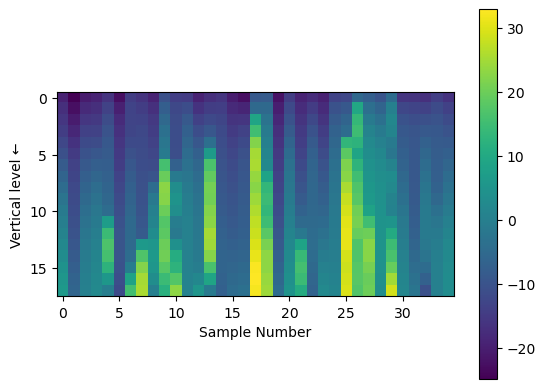

In [60]:

plt.imshow(10*np.log10(Z_meas[0].T))
plt.ylabel("Vertical level ←")
plt.xlabel("Sample Number")
plt.colorbar()

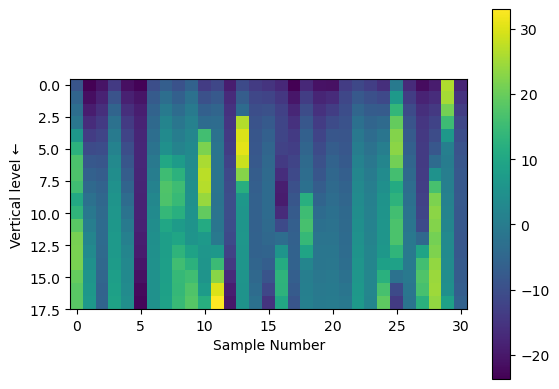

In [61]:

plt.imshow(10*np.log10(Z_meas[1].T))
plt.ylabel("Vertical level ←")
plt.xlabel("Sample Number")
plt.colorbar()

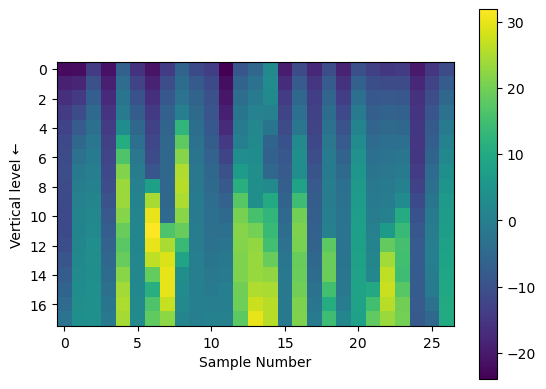

In [62]:

plt.imshow(10*np.log10(Z_meas[2].T))
plt.ylabel("Vertical level ←")
plt.xlabel("Sample Number")
plt.colorbar()

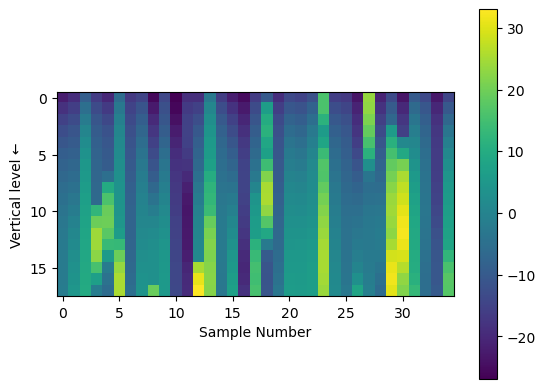

In [63]:

plt.imshow(10*np.log10(Z_meas[-1].T))
plt.ylabel("Vertical level ←")
plt.xlabel("Sample Number")
plt.colorbar()

In [64]:
def describe(arr):
    return {
        "count": arr.size,
        "mean": np.mean(arr),
        "std": np.std(arr),
        "min": np.min(arr),
        "5%": np.percentile(arr, 5),
        "25%": np.percentile(arr, 25),
        "50%": np.percentile(arr, 50),
        "75%": np.percentile(arr, 75),
        "95%": np.percentile(arr, 95),
        "max": np.max(arr),
    }


In [65]:
test_row["bulk_level_offset_top_m"]

array([    0.,  -120.,  -240.,  -360.,  -480.,  -600.,  -720.,  -840.,
        -960., -1080., -1200., -1320., -1440., -1560., -1680., -1800.,
       -1920., -2040.])

In [82]:
describe(bulk_data_filtered["Glaciation time [h]"])

{'count': 1489,
 'mean': np.float64(5.276527871054399),
 'std': np.float64(5.850396033335918),
 'min': np.float64(0.25),
 '5%': np.float64(0.5),
 '25%': np.float64(1.5),
 '50%': np.float64(3.25),
 '75%': np.float64(6.5),
 '95%': np.float64(17.149999999999977),
 'max': np.float64(56.75)}

In [81]:
describe(bulk_data_filtered["track_length"]/pd.Timedelta(minutes=60))

{'count': 1489,
 'mean': np.float64(16.458865010073875),
 'std': np.float64(12.374556398473876),
 'min': np.float64(1.0),
 '5%': np.float64(2.5),
 '25%': np.float64(7.5),
 '50%': np.float64(13.25),
 '75%': np.float64(22.25),
 '95%': np.float64(41.25),
 'max': np.float64(77.75)}

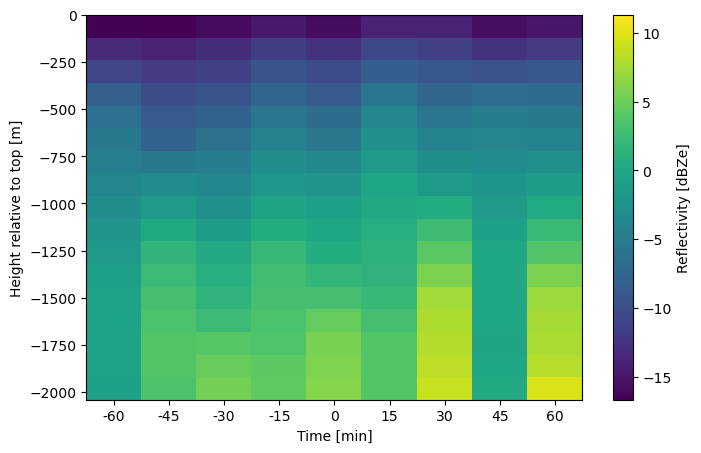

In [67]:

import numpy as np
import matplotlib.pyplot as plt

ind_range = [-4, 5]

inds = np.arange(ind_range[0], ind_range[1])   # -5, -4, ..., 4

# y_levels = test_row["bulk_level_offset_bottom_m"]
# or: 
y_levels = test_row["bulk_level_offset_top_m"]
plot_map = np.zeros((len(y_levels), len(inds)))

for col, ind in enumerate(inds):
    dbZ = 10*np.log10(Z_meas[ind])
    dbZ[~np.isfinite(dbZ)]=np.nan
    
    plot_map[:, col] = np.nanmean(dbZ,axis=0)

level_means = np.tile(plot_map.mean(axis=1)[:,np.newaxis],ind_range[1]-ind_range[0])


plt.figure(figsize=(8, 5))

plt.imshow(
    plot_map,
    aspect="auto",
    origin="upper",
    extent=[
        inds[0] - 0.5,
        inds[-1] + 0.5,
        test_row["bulk_level_offset_bottom_m"][-1],
        0,
    ],
)

# plt.hlines(-(np.argmax(plot_map-level_means,axis=0)+0.5)*120,inds-0.45, inds+0.45,linestyles="dashed",colors="black",linewidth=1)

plt.xticks(inds, inds*15)
plt.xlabel("Time [min]")
plt.ylabel("Height relative to top [m]")

plt.ylim(y_levels[-1], y_levels[0])  # bottom negative, top 0
plt.colorbar(label="Reflectivity [dBZe]")
plt.show() 

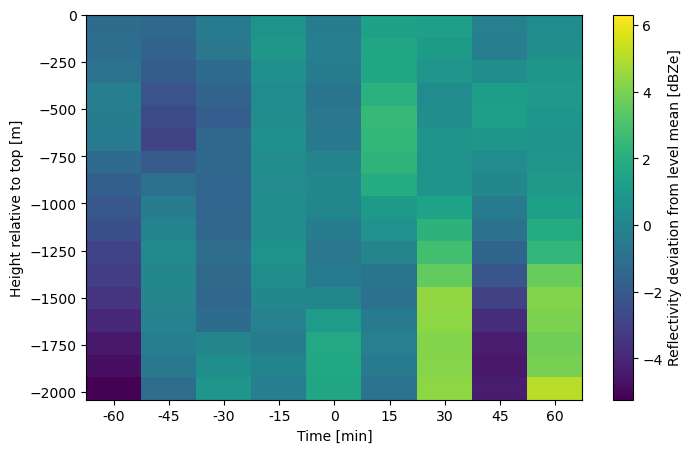

In [68]:

import numpy as np
import matplotlib.pyplot as plt

ind_range = [-4, 5]

inds = np.arange(ind_range[0], ind_range[1])   # -5, -4, ..., 4

# y_levels = test_row["bulk_level_offset_bottom_m"]
# or: 
y_levels = test_row["bulk_level_offset_top_m"]
plot_map = np.zeros((len(y_levels), len(inds)))

for col, ind in enumerate(inds):
    dbZ = 10*np.log10(Z_meas[ind])
    dbZ[~np.isfinite(dbZ)]=np.nan
    
    plot_map[:, col] = np.nanmean(dbZ,axis=0)

level_means = np.tile(plot_map.mean(axis=1)[:,np.newaxis],ind_range[1]-ind_range[0])


plt.figure(figsize=(8, 5))

plt.imshow(
    plot_map-level_means,
    aspect="auto",
    origin="upper",
    extent=[
        inds[0] - 0.5,
        inds[-1] + 0.5,
        test_row["bulk_level_offset_bottom_m"][-1],
        0,
    ],
)

# plt.hlines(-(np.argmax(plot_map-level_means,axis=0)+0.5)*120,inds-0.45, inds+0.45,linestyles="dashed",colors="black",linewidth=1)

plt.xticks(inds, inds*15)
plt.xlabel("Time [min]")
plt.ylabel("Height relative to top [m]")

plt.ylim(y_levels[-1], y_levels[0])  # bottom negative, top 0
plt.colorbar(label="Reflectivity deviation from level mean [dBZe]")
plt.show() 

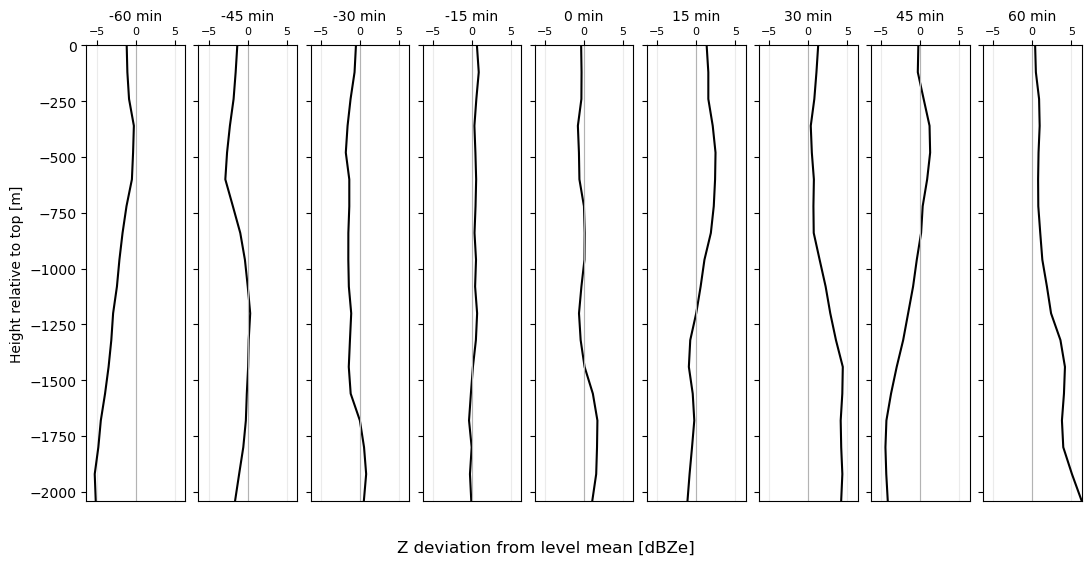

In [83]:
import numpy as np
import matplotlib.pyplot as plt

ind_range = [-4, 5]
inds = np.arange(ind_range[0], ind_range[1])

y_levels = test_row["bulk_level_offset_top_m"]
plot_map = np.zeros((len(y_levels), len(inds)))

for col, ind in enumerate(inds):
    dbZ = 10 * np.log10(Z_meas[ind])
    dbZ[~np.isfinite(dbZ)] = np.nan
    plot_map[:, col] = np.nanmean(dbZ, axis=0)

level_means = np.tile(
    plot_map.mean(axis=1)[:, np.newaxis],
    ind_range[1] - ind_range[0]
)

dev_map = plot_map - level_means


# Constant horizontal range for all vertical profiles
xmax = np.nanmax(np.abs(dev_map))
xlim = (-xmax, xmax)

fig, axes = plt.subplots(
    1,
    len(inds),
    figsize=(1.2 * len(inds), 5),
    sharey=True,
    constrained_layout=True
)

if len(inds) == 1:
    axes = [axes]

for ax, ind, profile in zip(axes, inds, dev_map.T):
    ax.plot(profile, y_levels, color="black", linewidth=1.5)

    max_i = np.nanargmax(profile)
    # ax.axhline(y_levels[max_i], linestyle="dashed", color="black", linewidth=1)

    ax.axvline(0, color="0.7", linewidth=0.8)

    # Same horizontal axis range everywhere
    ax.set_xlim(xlim)

    # Horizontal axes on top
    ax.xaxis.set_label_position("top")
    ax.xaxis.tick_top()
    ax.set_xlabel(f"{ind * 15} min")

    ax.tick_params(axis="x", labelsize=8)
    ax.grid(axis="x", alpha=0.25)

axes[0].set_ylabel("Height relative to top [m]")

plt.ylim(y_levels[-1], y_levels[0])
fig.supxlabel("Z deviation from level mean [dBZe]", y=-0.1)

plt.show()

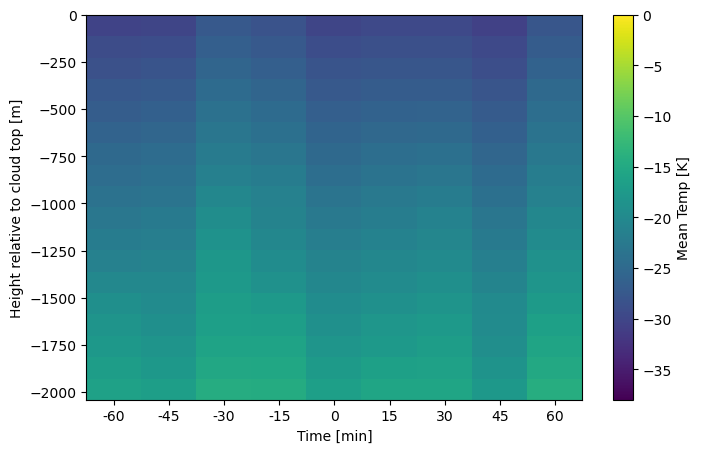

In [70]:
import numpy as np
import matplotlib.pyplot as plt

ind_range = [-4, 5]

inds = np.arange(ind_range[0], ind_range[1])   # -5, -4, ..., 4

# y_levels = test_row["bulk_level_offset_bottom_m"]
y_levels = test_row["bulk_level_offset_top_m"]

temp_plot_map = np.zeros((len(y_levels), len(inds)))

for col, ind in enumerate(inds):
    
    temp_plot_map[:, col] = np.nanmean(t_meas[ind],axis=0)

level_means = np.tile(temp_plot_map.mean(axis=1)[:,np.newaxis],ind_range[1]-ind_range[0])


plt.figure(figsize=(8, 5))

plt.imshow(
    temp_plot_map-273.15,
    aspect="auto",
    origin="upper",
    extent=[
        inds[0] - 0.5,
        inds[-1] + 0.5,
        y_levels[-1],
        y_levels[0],
    ],
    vmin=-38,
    vmax=0
)

plt.xticks(inds, inds*15)
plt.xlabel("Time [min]")
plt.ylabel("Height relative to cloud top [m]")

plt.ylim(y_levels[-1], y_levels[0])  # bottom negative, top 0
plt.colorbar(label="Mean Temp [K]")

plt.show()

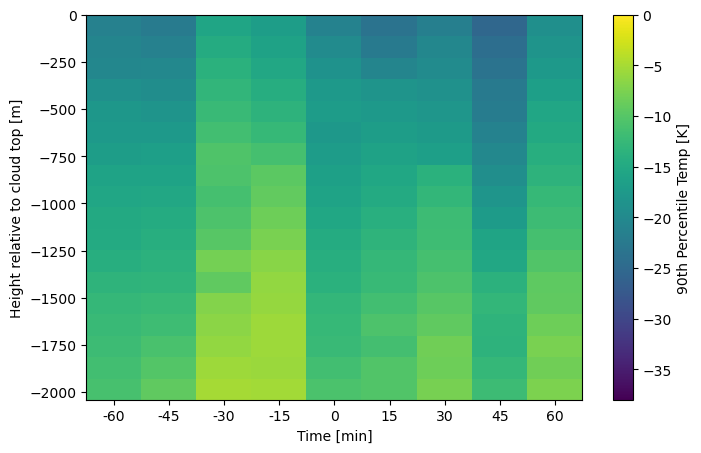

In [71]:
import numpy as np
import matplotlib.pyplot as plt

ind_range = [-4, 5]

inds = np.arange(ind_range[0], ind_range[1])   # -5, -4, ..., 4

# y_levels = test_row["bulk_level_offset_bottom_m"]
y_levels = test_row["bulk_level_offset_top_m"]

temp_plot_map = np.zeros((len(y_levels), len(inds)))

for col, ind in enumerate(inds):
    
    temp_plot_map[:, col] = np.nanpercentile(t_meas[ind],90,axis=0)


plt.figure(figsize=(8, 5))

plt.imshow(
    temp_plot_map-273.15,
    aspect="auto",
    origin="upper",
    extent=[
        inds[0] - 0.5,
        inds[-1] + 0.5,
        y_levels[-1],
        y_levels[0],
    ],
    vmin=-38,
    vmax=0
)

plt.xticks(inds, inds*15)
plt.xlabel("Time [min]")
plt.ylabel("Height relative to cloud top [m]")

plt.ylim(y_levels[-1], y_levels[0])  # bottom negative, top 0
plt.colorbar(label="90th Percentile Temp [K]")

plt.show()

In [72]:
describe(Z_meas[-2])

{'count': 486,
 'mean': np.float32(151.91054),
 'std': np.float32(1198.8113),
 'min': np.float32(0.0010585886),
 '5%': np.float32(0.009736398),
 '25%': np.float32(0.072805755),
 '50%': np.float32(0.32144183),
 '75%': np.float32(1.8579007),
 '95%': np.float32(191.74397),
 'max': np.float32(17305.006)}

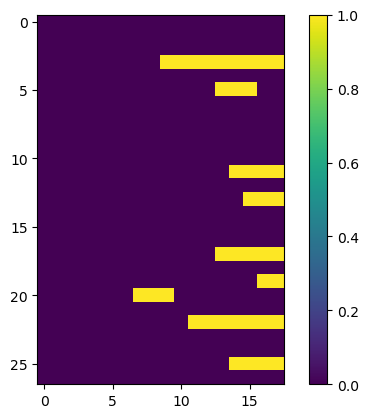

In [73]:
Z_meas[-2]
plt.imshow(Z_meas[-2]>50)
plt.colorbar()

In [74]:
# raw_df = pd.read_parquet("/cluster/work/climate/dnikolo/MSGI/development/iwc_rel_df_V3_1_2007.parquet")

## Mean Version

In [75]:
stats_by_rel_time

,rel_ind,n_hits,mean_iwc_profile,mean_Z_profile,mean_ext_profile,mean_temp_profile,mean_bulk_height_profile_m,bulk_offset_top_m,bulk_offset_bottom_m,dd_cth,sev_cth,dd_ctt,mean_iwc_ct,sev_ctt,mean_area_km,rel_time_min
0,-237,1,"[4.1333765e-06, 5.752144e-06, 7.5360463e-06, 9...","[0.007036876, 0.012312477, 0.018463943, 0.0245...","[0.00014636954, 0.00020352412, 0.0002631762, 0...","[233.97858, 234.7026, 235.43147, 236.26764, 23...","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....",5.622109,4866.451039,233.978577,0.000004,240.180201,20116.688535,-3555
1,-235,1,"[6.9375114e-06, 1.2257575e-05, 1.923796e-05, 2...","[0.047485724, 0.11255338, 0.20632966, 0.300939...","[0.00018007883, 0.0003141136, 0.00047593017, 0...","[241.27295, 242.17288, 242.92459, 243.61812, 2...","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....",7.685505,6584.499430,241.272949,0.000007,246.152981,156235.496425,-3525
2,-191,1,"[3.189197e-05, 3.5949237e-05, 3.229844e-05, 2....","[0.012870546, 0.021171581, 0.029984586, 0.0316...","[0.0019483331, 0.002041507, 0.0016774791, 0.00...","[256.4819, 257.1704, 257.99213, 258.8837, 259....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....",3.746890,3704.568968,256.481903,0.000032,258.371809,42926.886609,-2865
3,-178,2,"[3.6838865e-05, 3.2742264e-05, 3.170894e-05, 6...","[5.5233, 25.056936, 140.56805, 886.1939, 3022....","[0.00022704765, 0.0002154616, 0.0002046761, 0....","[250.21045, 250.53049, 250.83337, 251.5709, 25...","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....",1.888322,2033.451054,250.210442,0.000037,249.886662,242096.907311,-2670
4,-171,1,"[6.9394937e-06, 4.0359596e-06, 3.6298259e-06, ...","[0.003213857, 19.292568, 150.02078, 410.75204,...","[2.128538e-05, 1.5626898e-05, 1.52454195e-05, ...","[260.5071, 261.31537, 262.1077, 262.7502, 262....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....",1.219781,1720.205315,260.507111,0.000007,258.157829,298164.903928,-2565
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
221,133,1,"[2.6531707e-06, 3.2926678e-06, 3.913884e-06, 4...","[0.0034682995, 0.0072614406, 0.012247726, 0.01...","[3.6438403e-05, 6.162651e-05, 8.829519e-05, 0....","[245.14941, 245.77998, 246.49289, 247.2311, 24...","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....",6.835588,6450.176940,245.149414,0.000003,246.133802,121647.131666,1995
222,135,1,"[4.8400602e-06, 7.23097e-06, 1.0763274e-05, 1....","[0.027026812, 0.05622481, 0.09936894, 0.141066...","[0.00011999376, 0.00017414901, 0.00023670889, ...","[242.17374, 242.84634, 243.82594, 245.1301, 24...","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....",4.693939,5325.863517,242.173737,0.000005,240.698474,44023.674165,2025
223,144,1,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[0.0022995537, 0.0024746289, 0.0022131882, 0.0...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....",NaN,3070.186964,NaN,NaN,268.340821,62996.533863,2160
224,161,1,"[1.47816745e-05, 2.0356436e-05, 2.6128524e-05,...","[0.018750148, 0.05012421, 0.105603024, 0.22439...","[0.0004950565, 0.0006133751, 0.0007785886, 0.0...","[244.388,

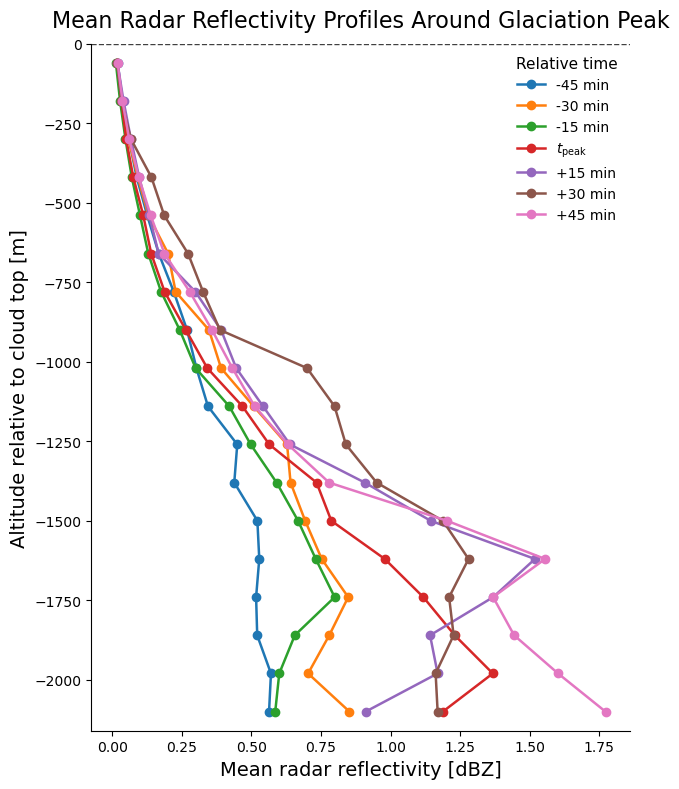

In [76]:
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Times to plot
# ------------------------------------------------------------
target_times = [-45, -30, -15, 0, 15, 30, 45]

df_plot = (
    stats_by_rel_time[
        stats_by_rel_time["rel_time_min"].isin(target_times)
    ]
    .sort_values("rel_time_min")
    .copy()
)

missing = sorted(set(target_times) - set(df_plot["rel_time_min"]))
if missing:
    print(f"Warning: missing requested relative times: {missing}")

# ------------------------------------------------------------
# Plot mean dBZ profile at each relative time
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(6.5, 8))

for _, row in df_plot.iterrows():
    rel_time = row["rel_time_min"]

    top = np.asarray(row["bulk_offset_top_m"], dtype=float)
    bottom = np.asarray(row["bulk_offset_bottom_m"], dtype=float)
    z_dbz = np.asarray(row["mean_Z_profile"], dtype=float)

    n = min(len(top), len(bottom), len(z_dbz))
    top = top[:n]
    bottom = bottom[:n]
    z_dbz = z_dbz[:n]

    # Use bin midpoint as vertical coordinate
    height_mid = 0.5 * (top + bottom)

    mask = (
        np.isfinite(height_mid)
        & np.isfinite(z_dbz)
    )

    height_mid = height_mid[mask]
    z_dbz = z_dbz[mask]

    # Sort vertically
    order = np.argsort(height_mid)
    height_mid = height_mid[order]
    z_dbz = z_dbz[order]

    if rel_time == 0:
        label = r"$t_{\mathrm{peak}}$"
    elif rel_time < 0:
        label = f"{rel_time} min"
    else:
        label = f"+{rel_time} min"

    ax.plot(
        z_dbz,
        height_mid,
        marker="o",
        linewidth=1.8,
        label=label,
    )

# ------------------------------------------------------------
# Styling
# ------------------------------------------------------------
ax.axhline(
    0,
    linestyle="--",
    linewidth=1.0,
    color="0.25"
)

ax.set_xlabel("Mean radar reflectivity [dBZ]", fontsize=14)
ax.set_ylabel("Altitude relative to cloud top [m]", fontsize=14)

ax.set_title(
    "Mean Radar Reflectivity Profiles Around Glaciation Peak",
    fontsize=16,
    pad=12,
)

ax.set_ylim(
    np.nanmin([
        np.nanmin(np.asarray(v, dtype=float))
        for v in df_plot["bulk_offset_bottom_m"]
    ]),
    0
)

ax.legend(
    title="Relative time",
    frameon=False,
    fontsize=10,
    title_fontsize=11,
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    "mean_radar_reflectivity_profiles_by_relative_time.png",
    transparent=True,
    bbox_inches="tight",
    dpi=300,
)

plt.show()

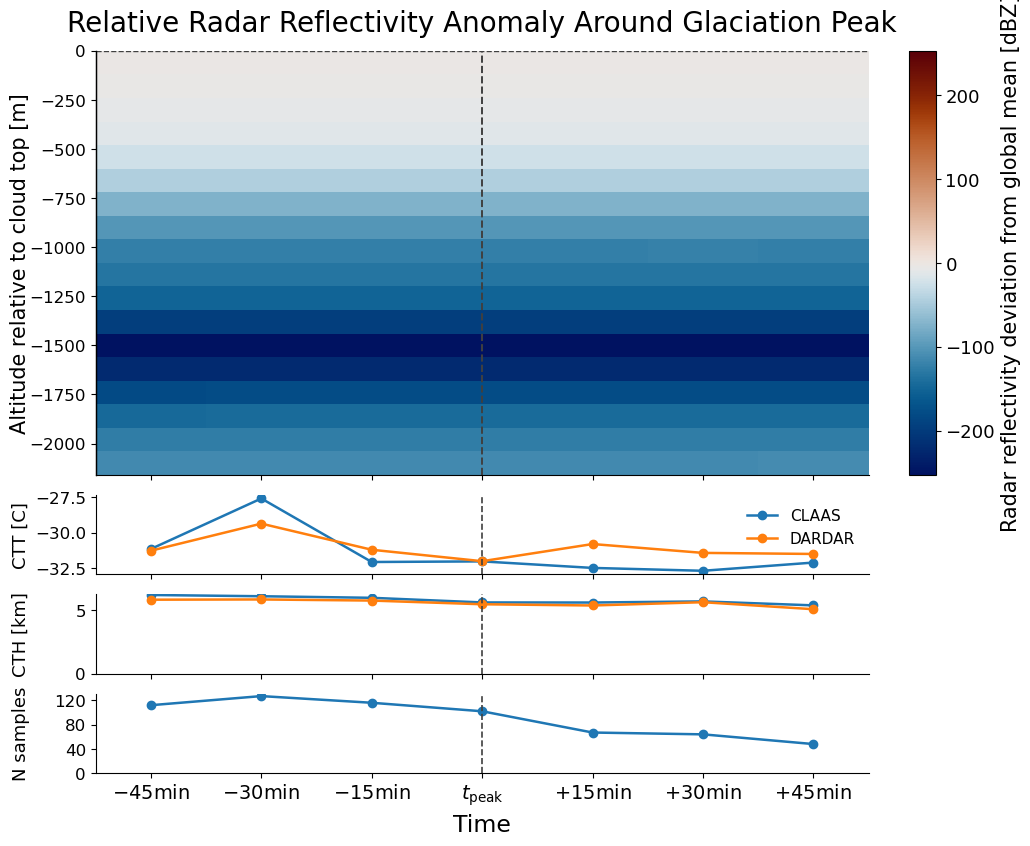

In [77]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Rectangle
from matplotlib.gridspec import GridSpec
from matplotlib.ticker import MaxNLocator
from cmcrameri import cm

# ------------------------------------------------------------
# Times to plot
# ------------------------------------------------------------
target_times = [-45, -30, -15, 0, 15, 30, 45]

df_plot = (
    stats_by_rel_time[
        stats_by_rel_time["rel_time_min"].isin(target_times)
    ]
    .sort_values("rel_time_min")
    .copy()
)

missing = sorted(set(target_times) - set(df_plot["rel_time_min"]))
if missing:
    print(f"Warning: missing requested relative times: {missing}")

# ------------------------------------------------------------
# Compute all-time mean radar reflectivity profile by vertical level
# ------------------------------------------------------------
level_values = {}

for _, row in stats_by_rel_time.iterrows():
    top = np.asarray(row["bulk_offset_top_m"], dtype=float)
    bottom = np.asarray(row["bulk_offset_bottom_m"], dtype=float)
    z = np.asarray(row["mean_Z_profile"], dtype=float)

    n = min(len(top), len(bottom), len(z))
    top = top[:n]
    bottom = bottom[:n]
    z = z[:n]

    mask = (
        np.isfinite(top)
        & np.isfinite(bottom)
        & np.isfinite(z)
    )

    for t, b, val in zip(top[mask], bottom[mask], z[mask]):
        key = (float(t), float(b))
        level_values.setdefault(key, []).append(val)

all_time_mean_by_level = {
    key: np.nanmean(vals)
    for key, vals in level_values.items()
}

# ------------------------------------------------------------
# Build radar reflectivity anomaly records
# ------------------------------------------------------------
records = []

for _, row in df_plot.iterrows():
    rel_time = row["rel_time_min"]

    top = np.asarray(row["bulk_offset_top_m"], dtype=float)
    bottom = np.asarray(row["bulk_offset_bottom_m"], dtype=float)
    z = np.asarray(row["mean_Z_profile"], dtype=float)

    n = min(len(top), len(bottom), len(z))
    top = top[:n]
    bottom = bottom[:n]
    z = z[:n]

    mask = (
        np.isfinite(top)
        & np.isfinite(bottom)
        & np.isfinite(z)
    )

    top = top[mask]
    bottom = bottom[mask]
    z = z[mask]

    for t, b, val in zip(top, bottom, z):
        key = (float(t), float(b))
        mean_val = all_time_mean_by_level.get(key, np.nan)

        if np.isfinite(mean_val):
            anomaly = val - mean_val  # dBZ anomaly
        else:
            anomaly = np.nan

        records.append(
            {
                "rel_time_min": rel_time,
                "top": t,
                "bottom": b,
                "anomaly": anomaly,
            }
        )

anomaly_vals = np.asarray([
    r["anomaly"] for r in records
    if np.isfinite(r["anomaly"])
])

if len(anomaly_vals) == 0:
    raise ValueError("No finite radar reflectivity anomaly values found.")

absmax = np.nanmax(np.abs(anomaly_vals))

norm = TwoSlopeNorm(
    vmin=-absmax,
    vcenter=0,
    vmax=absmax
)

cmap = cm.vik

# ------------------------------------------------------------
# Figure layout: heatmap + 3 shallow line plots + colorbar column
# ------------------------------------------------------------
fig = plt.figure(figsize=(10.5, 8.6))
fig.patch.set_alpha(0)

gs = GridSpec(
    nrows=4,
    ncols=2,
    width_ratios=[1, 0.035],
    height_ratios=[5.6, 1.05, 1.05, 1.05],
    hspace=0.12,
    wspace=0.10
)

ax = fig.add_subplot(gs[0, 0])
ax_ctt = fig.add_subplot(gs[1, 0], sharex=ax)
ax_cth = fig.add_subplot(gs[2, 0], sharex=ax)
ax_hits = fig.add_subplot(gs[3, 0], sharex=ax)

# Dedicated colorbar axis, only next to the heatmap
cax = fig.add_subplot(gs[0, 1])

for a in [ax, ax_ctt, ax_cth, ax_hits]:
    a.set_facecolor("none")

cax.set_facecolor("none")

# ------------------------------------------------------------
# Main radar reflectivity anomaly heatmap
# ------------------------------------------------------------
x_width = 15.0

for rel_time in df_plot["rel_time_min"].values:
    row_records = [
        r for r in records
        if r["rel_time_min"] == rel_time
        and np.isfinite(r["anomaly"])
    ]

    if len(row_records) == 0:
        continue

    x_left = rel_time - x_width / 2

    row_records = sorted(
        row_records,
        key=lambda r: min(r["top"], r["bottom"])
    )

    for r in row_records:
        y_low = min(r["top"], r["bottom"])
        height = abs(r["bottom"] - r["top"])

        rect = Rectangle(
            (x_left, y_low),
            x_width,
            height,
            facecolor=cmap(norm(r["anomaly"])),
            edgecolor="none",
            hatch=None,
            zorder=1
        )
        ax.add_patch(rect)

    # Add hatched gaps between vertical bins, if any
    intervals = []

    for r in row_records:
        y0 = min(r["top"], r["bottom"])
        y1 = max(r["top"], r["bottom"])
        intervals.append((y0, y1))

    intervals = sorted(intervals, key=lambda p: p[0])

    for (prev_low, prev_high), (next_low, next_high) in zip(
        intervals[:-1],
        intervals[1:]
    ):
        if next_low > prev_high and not np.isclose(next_low, prev_high):
            gap_low = prev_high
            gap_height = next_low - prev_high

            gap_rect = Rectangle(
                (x_left, gap_low),
                x_width,
                gap_height,
                facecolor="white",
                edgecolor="0.4",
                hatch="///",
                linewidth=0.0,
                zorder=2
            )
            ax.add_patch(gap_rect)

# ------------------------------------------------------------
# Colorbar
# ------------------------------------------------------------
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

cbar = fig.colorbar(sm, cax=cax)
cbar.set_label(
    "Radar reflectivity deviation from global mean [dBZ]",
    fontsize=15
)
cbar.ax.tick_params(labelsize=13)

# ------------------------------------------------------------
# Main axis styling
# ------------------------------------------------------------
ax.set_title(
    "Relative Radar Reflectivity Anomaly Around Glaciation Peak",
    fontsize=20,
    pad=14,
)

ax.set_ylabel("Altitude relative to cloud top [m]", fontsize=17)

all_tops = np.concatenate([
    np.asarray(v, dtype=float)
    for v in df_plot["bulk_offset_top_m"]
])

all_bottoms = np.concatenate([
    np.asarray(v, dtype=float)
    for v in df_plot["bulk_offset_bottom_m"]
])

ax.set_ylim(
    np.nanmin([all_tops.min(), all_bottoms.min()]),
    0
)

ax.axvline(
    0,
    linestyle="--",
    linewidth=1.4,
    color="0.25",
    zorder=4
)

ax.axhline(
    0,
    linestyle="--",
    linewidth=1.0,
    color="0.25",
    zorder=4
)

# Hide x tick labels on upper panel
plt.setp(ax.get_xticklabels(), visible=False)

# ------------------------------------------------------------
# Cloud top temperature line plot
# ------------------------------------------------------------
times = df_plot["rel_time_min"].to_numpy(dtype=float)

ax_ctt.plot(
    times,
    df_plot["sev_ctt"].to_numpy(dtype=float) - 273.15,
    marker="o",
    linewidth=1.8,
    label="CLAAS"
)

ax_ctt.plot(
    times,
    df_plot["dd_ctt"].to_numpy(dtype=float) - 273.15,
    marker="o",
    linewidth=1.8,
    label="DARDAR"
)

ax_ctt.axvline(
    0,
    linestyle="--",
    linewidth=1.2,
    color="0.25"
)

ax_ctt.set_ylabel("CTT [C]", fontsize=13)
ax_ctt.tick_params(axis="y", labelsize=12)
ax_ctt.legend(
    frameon=False,
    fontsize=11,
    loc="upper right"
)

plt.setp(ax_ctt.get_xticklabels(), visible=False)

# ------------------------------------------------------------
# Mean cloud top height line plot
# ------------------------------------------------------------
ax_cth.plot(
    times,
    df_plot["dd_cth"].to_numpy(dtype=float),
    marker="o",
    linewidth=1.8,
    label="DARDAR"
)

ax_cth.plot(
    times,
    df_plot["sev_cth"].to_numpy(dtype=float) / 1000,
    marker="o",
    linewidth=1.8,
    label="CLAAS"
)

ax_cth.axvline(
    0,
    linestyle="--",
    linewidth=1.2,
    color="0.25"
)

ax_cth.set_ylabel("CTH [km]", fontsize=13)
ax_cth.tick_params(axis="y", labelsize=12)
ax_cth.set_ylim(0)

plt.setp(ax_cth.get_xticklabels(), visible=False)

# ------------------------------------------------------------
# n_hits line plot
# ------------------------------------------------------------
ax_hits.plot(
    times,
    df_plot["n_hits"].to_numpy(dtype=float),
    marker="o",
    linewidth=1.8
)

ax_hits.axvline(
    0,
    linestyle="--",
    linewidth=1.2,
    color="0.25"
)

ax_hits.set_ylabel("N samples", fontsize=13)
ax_hits.tick_params(axis="y", labelsize=12)
ax_hits.yaxis.set_major_locator(
    MaxNLocator(nbins=4, integer=True)
)
ax_hits.set_ylim(0)

# ------------------------------------------------------------
# Consistent y-axis label styling and alignment
# ------------------------------------------------------------
ylabel_fontsize = 13
ylabel_pad = 42

for a in [ax, ax_ctt, ax_cth, ax_hits]:
    a.yaxis.label.set_size(ylabel_fontsize)
    a.yaxis.labelpad = ylabel_pad
    a.yaxis.set_label_coords(-0.085, 0.5)
    a.tick_params(axis="y", labelsize=12)

# Make main heatmap label slightly larger
ax.yaxis.label.set_size(15)

# ------------------------------------------------------------
# Shared x-axis formatting
# ------------------------------------------------------------
ax_hits.set_xlim(
    min(target_times) - x_width / 2,
    max(target_times) + x_width / 2,
)

ax_hits.set_xlabel("Time", fontsize=17)

ax_hits.set_xticks(target_times)

ax_hits.set_xticklabels(
    [
        r"$- 45\mathrm{min}$",
        r"$- 30\mathrm{min}$",
        r"$- 15\mathrm{min}$",
        r"$t_{\mathrm{peak}}$",
        r"$+ 15\mathrm{min}$",
        r"$+ 30\mathrm{min}$",
        r"$+ 45\mathrm{min}$",
    ],
    fontsize=14,
)

# ------------------------------------------------------------
# Clean style
# ------------------------------------------------------------
for a in [ax, ax_ctt, ax_cth, ax_hits]:
    a.spines["top"].set_visible(False)
    a.spines["right"].set_visible(False)
    a.spines["left"].set_zorder(10)
    a.spines["bottom"].set_zorder(10)

# Redraw left axis line on heatmap, if patches cover it
ax.axvline(
    ax.get_xlim()[0],
    color="black",
    linewidth=1.0,
    zorder=10,
    clip_on=False
)

fig.subplots_adjust(
    left=0.10,
    right=0.90,
    top=0.94,
    bottom=0.10
)

plt.savefig(
    "relative_radar_reflectivity_anomaly_heatmap_with_ctt_cth_nhits_panels.png",
    transparent=True,
    bbox_inches="tight",
    dpi=300,
)

plt.show()

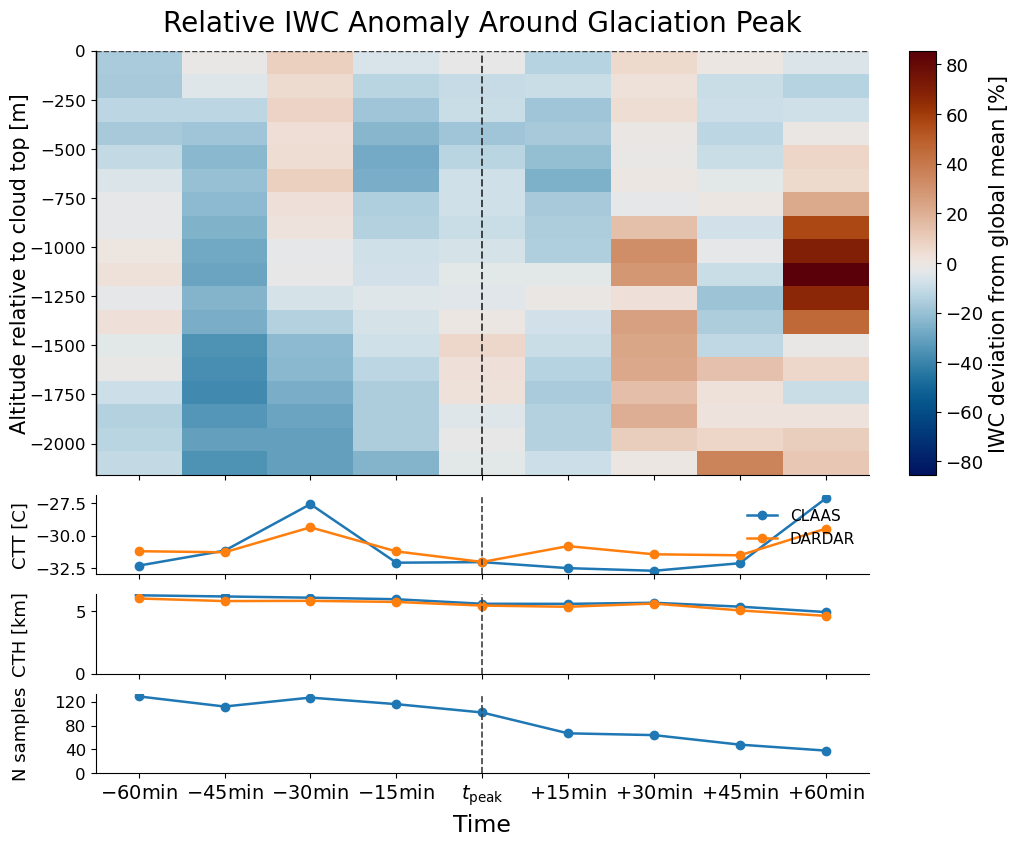

In [78]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Rectangle
from matplotlib.gridspec import GridSpec
from matplotlib.ticker import MaxNLocator
from cmcrameri import cm

# ------------------------------------------------------------
# Times to plot
# ------------------------------------------------------------
target_times = [ -60, -45, -30, -15, 0, 15, 30, 45, 60]

df_plot = (
    stats_by_rel_time[
        stats_by_rel_time["rel_time_min"].isin(target_times)
    ]
    .sort_values("rel_time_min")
    .copy()
)

missing = sorted(set(target_times) - set(df_plot["rel_time_min"]))
if missing:
    print(f"Warning: missing requested relative times: {missing}")

# ------------------------------------------------------------
# Compute all-time mean profile by actual vertical level
# ------------------------------------------------------------
level_values = {}

for _, row in stats_by_rel_time.iterrows():
    top = np.asarray(row["bulk_offset_top_m"], dtype=float)
    bottom = np.asarray(row["bulk_offset_bottom_m"], dtype=float)
    z = np.asarray(row["mean_iwc_profile"], dtype=float)

    n = min(len(top), len(bottom), len(z))
    top = top[:n]
    bottom = bottom[:n]
    z = z[:n]

    mask = (
        np.isfinite(top)
        & np.isfinite(bottom)
        & np.isfinite(z)
        & (z > 0)
    )

    for t, b, val in zip(top[mask], bottom[mask], z[mask]):
        key = (float(t), float(b))
        level_values.setdefault(key, []).append(val)

all_time_mean_by_level = {
    key: np.nanmean(vals)
    for key, vals in level_values.items()
}
# mean_iwc_all = np.nanmean(
#     np.stack(stats_by_rel_time["mean_iwc_profile"].to_numpy())
# )
# all_time_mean_by_level = {
#     key: mean_iwc_all
#     for key, vals in level_values.items()
# }


# ------------------------------------------------------------
# Build anomaly records
# ------------------------------------------------------------
records = []

for _, row in df_plot.iterrows():
    rel_time = row["rel_time_min"]

    top = np.asarray(row["bulk_offset_top_m"], dtype=float)
    bottom = np.asarray(row["bulk_offset_bottom_m"], dtype=float)
    z = np.asarray(row["mean_iwc_profile"], dtype=float)

    n = min(len(top), len(bottom), len(z))
    top = top[:n]
    bottom = bottom[:n]
    z = z[:n]

    mask = (
        np.isfinite(top)
        & np.isfinite(bottom)
        & np.isfinite(z)
        & (z > 0)
    )

    top = top[mask]
    bottom = bottom[mask]
    z = z[mask]

    for t, b, val in zip(top, bottom, z):
        key = (float(t), float(b))
        mean_val = all_time_mean_by_level.get(key, np.nan)

        if np.isfinite(mean_val) and mean_val > 0:
            anomaly = 100 * (val - mean_val) / mean_val
        else:
            anomaly = np.nan

        records.append(
            {
                "rel_time_min": rel_time,
                "top": t,
                "bottom": b,
                "anomaly": anomaly,
            }
        )

anomaly_vals = np.asarray([
    r["anomaly"] for r in records
    if np.isfinite(r["anomaly"])
])

absmax = np.nanmax(np.abs(anomaly_vals))

norm = TwoSlopeNorm(
    vmin=-absmax,
    vcenter=0,
    vmax=absmax
)

cmap = cm.vik

# ------------------------------------------------------------
# Figure layout: heatmap + 3 shallow line plots + colorbar column
# ------------------------------------------------------------
fig = plt.figure(figsize=(10.5, 8.6))
fig.patch.set_alpha(0)

gs = GridSpec(
    nrows=4,
    ncols=2,
    width_ratios=[1, 0.035],
    height_ratios=[5.6, 1.05, 1.05, 1.05],
    hspace=0.12,
    wspace=0.10
)

ax = fig.add_subplot(gs[0, 0])
ax_ctt = fig.add_subplot(gs[1, 0], sharex=ax)
ax_cth = fig.add_subplot(gs[2, 0], sharex=ax)
ax_hits = fig.add_subplot(gs[3, 0], sharex=ax)

# dedicated colorbar axis, only next to the heatmap
cax = fig.add_subplot(gs[0, 1])

for a in [ax, ax_ctt, ax_cth, ax_hits]:
    a.set_facecolor("none")

cax.set_facecolor("none")

# ------------------------------------------------------------
# Main heatmap
# ------------------------------------------------------------
x_width = 15.0

for rel_time in df_plot["rel_time_min"].values:
    row_records = [
        r for r in records
        if r["rel_time_min"] == rel_time
        and np.isfinite(r["anomaly"])
    ]

    if len(row_records) == 0:
        continue

    x_left = rel_time - x_width / 2

    row_records = sorted(row_records, key=lambda r: min(r["top"], r["bottom"]))

    for r in row_records:
        y_low = min(r["top"], r["bottom"])
        height = abs(r["bottom"] - r["top"])

        rect = Rectangle(
            (x_left, y_low),
            x_width,
            height,
            facecolor=cmap(norm(r["anomaly"])),
            edgecolor="none",
            hatch=None,
            zorder=1
        )
        ax.add_patch(rect)

    intervals = []

    for r in row_records:
        y0 = min(r["top"], r["bottom"])
        y1 = max(r["top"], r["bottom"])
        intervals.append((y0, y1))

    intervals = sorted(intervals, key=lambda p: p[0])

    for (prev_low, prev_high), (next_low, next_high) in zip(intervals[:-1], intervals[1:]):
        if next_low > prev_high and not np.isclose(next_low, prev_high):
            gap_low = prev_high
            gap_height = next_low - prev_high

            gap_rect = Rectangle(
                (x_left, gap_low),
                x_width,
                gap_height,
                facecolor="white",
                edgecolor="0.4",
                hatch="///",
                linewidth=0.0,
                zorder=2
            )
            ax.add_patch(gap_rect)

# ------------------------------------------------------------
# Colorbar
# ------------------------------------------------------------
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

cbar = fig.colorbar(sm, cax=cax)
cbar.set_label("IWC deviation from global mean [%]", fontsize=15)
cbar.ax.tick_params(labelsize=13)

# ------------------------------------------------------------
# Main axis styling
# ------------------------------------------------------------
ax.set_title(
    "Relative IWC Anomaly Around Glaciation Peak",
    fontsize=20,
    pad=14,
)

ax.set_ylabel("Altitude relative to cloud top [m]", fontsize=17)

all_tops = np.concatenate([
    np.asarray(v, dtype=float)
    for v in df_plot["bulk_offset_top_m"]
])

all_bottoms = np.concatenate([
    np.asarray(v, dtype=float)
    for v in df_plot["bulk_offset_bottom_m"]
])

ax.set_ylim(
    np.nanmin([all_tops.min(), all_bottoms.min()]),
    0
)

ax.axvline(
    0,
    linestyle="--",
    linewidth=1.4,
    color="0.25",
    zorder=4
)

ax.axhline(
    0,
    linestyle="--",
    linewidth=1.0,
    color="0.25",
    zorder=4
)

# Hide x tick labels on upper panels
plt.setp(ax.get_xticklabels(), visible=False)

# ------------------------------------------------------------
# Cloud top temperature line plot
# ------------------------------------------------------------
times = df_plot["rel_time_min"].to_numpy(dtype=float)

ax_ctt.plot(
    times,
    df_plot["sev_ctt"].to_numpy(dtype=float) - 273.15,
    marker="o",
    linewidth=1.8,
    label="CLAAS"
)

ax_ctt.plot(
    times,
    df_plot["dd_ctt"].to_numpy(dtype=float) - 273.15,
    marker="o",
    linewidth=1.8,
    label="DARDAR"
)

ax_ctt.axvline(
    0,
    linestyle="--",
    linewidth=1.2,
    color="0.25"
)

ax_ctt.set_ylabel("CTT [C]", fontsize=13)
ax_ctt.tick_params(axis="y", labelsize=12)
ax_ctt.legend(
    frameon=False,
    fontsize=11,
    loc="upper right"
)

plt.setp(ax_ctt.get_xticklabels(), visible=False)

# ------------------------------------------------------------
# Mean cloud top height line plot
# ------------------------------------------------------------
ax_cth.plot(
    times,
    df_plot["dd_cth"].to_numpy(dtype=float),
    marker="o",
    linewidth=1.8
)
ax_cth.plot(
    times,
    df_plot["sev_cth"].to_numpy(dtype=float)/1000,
    marker="o",
    linewidth=1.8
)

ax_cth.axvline(
    0,
    linestyle="--",
    linewidth=1.2,
    color="0.25"
)

ax_cth.set_ylabel("CTH [km]", fontsize=13)
ax_cth.tick_params(axis="y", labelsize=12)
ax_cth.set_ylim(0)
plt.setp(ax_cth.get_xticklabels(), visible=False)

# ------------------------------------------------------------
# n_hits line plot
# ------------------------------------------------------------
ax_hits.plot(
    times,
    df_plot["n_hits"].to_numpy(dtype=float),
    marker="o",
    linewidth=1.8
)

ax_hits.axvline(
    0,
    linestyle="--",
    linewidth=1.2,
    color="0.25"
)

ax_hits.set_ylabel("N samples", fontsize=13)
ax_hits.tick_params(axis="y", labelsize=12)
ax_hits.yaxis.set_major_locator(
    MaxNLocator(nbins=4, integer=True)
)
ax_hits.set_ylim(0)

# ------------------------------------------------------------
# Consistent y-axis label styling and alignment
# ------------------------------------------------------------
ylabel_fontsize = 13
ylabel_pad = 42

for a in [ax, ax_ctt, ax_cth, ax_hits]:
    a.yaxis.label.set_size(ylabel_fontsize)
    a.yaxis.labelpad = ylabel_pad
    a.yaxis.set_label_coords(-0.085, 0.5)
    a.tick_params(axis="y", labelsize=12)

# Make main heatmap label slightly larger only if desired
ax.yaxis.label.set_size(15)
# ------------------------------------------------------------
# Shared x-axis formatting
# ------------------------------------------------------------
ax_hits.set_xlim(
    min(target_times) - x_width / 2,
    max(target_times) + x_width / 2,
)

ax_hits.set_xlabel("Time", fontsize=17)

ax_hits.set_xticks(target_times)


ax_hits.set_xticklabels(
    [
        r"$- 60\mathrm{min}$",
        r"$- 45\mathrm{min}$",
        r"$- 30\mathrm{min}$",
        r"$- 15\mathrm{min}$",
        r"$t_{\mathrm{peak}}$",
        r"$+ 15\mathrm{min}$",
        r"$+ 30\mathrm{min}$",
        r"$+ 45\mathrm{min}$",
        r"$+ 60\mathrm{min}$",
    ],
    fontsize=14,
)

# ------------------------------------------------------------
# Clean style
# ------------------------------------------------------------
for a in [ax, ax_ctt, ax_cth, ax_hits]:
    a.spines["top"].set_visible(False)
    a.spines["right"].set_visible(False)
    a.spines["left"].set_zorder(10)
    a.spines["bottom"].set_zorder(10)

# redraw left axis line on heatmap, if patches cover it
ax.axvline(
    ax.get_xlim()[0],
    color="black",
    linewidth=1.0,
    zorder=10,
    clip_on=False
)

fig.subplots_adjust(
    left=0.10,
    right=0.90,
    top=0.94,
    bottom=0.10
)

plt.savefig(
    "relative_iwc_anomaly_heatmap_with_ctt_cth_nhits_panels.png",
    transparent=True,
    bbox_inches="tight",
    dpi=300,
)

plt.show()

# Development

In [79]:
mean_iwc_all = np.nanmean(
    np.stack(stats_by_rel_time["mean_iwc_profile"].to_numpy())
)
mean_iwc_all
all_time_mean_by_level = {
    key: np.nanmean(vals)
    for key, vals in level_values.items()
}
all_time_mean_by_level


{(0.0, -120.0): np.float64(7.47254121995817e-06),
 (-120.0, -240.0): np.float64(1.1022956885042845e-05),
 (-240.0, -360.0): np.float64(1.5094297950467097e-05),
 (-360.0, -480.0): np.float64(1.934703652090824e-05),
 (-480.0, -600.0): np.float64(2.290931922439248e-05),
 (-600.0, -720.0): np.float64(2.5694540704129004e-05),
 (-720.0, -840.0): np.float64(2.7706415534416757e-05),
 (-840.0, -960.0): np.float64(3.049727807941898e-05),
 (-960.0, -1080.0): np.float64(3.194837064869814e-05),
 (-1080.0, -1200.0): np.float64(3.4453467518312614e-05),
 (-1200.0, -1320.0): np.float64(3.674332067944938e-05),
 (-1320.0, -1440.0): np.float64(3.9173859698415564e-05),
 (-1440.0, -1560.0): np.float64(4.065625102760966e-05),
 (-1560.0, -1680.0): np.float64(4.236325166490508e-05),
 (-1680.0, -1800.0): np.float64(4.551090004733933e-05),
 (-1800.0, -1920.0): np.float64(4.6891128623059715e-05),
 (-1920.0, -2040.0): np.float64(4.937733575206539e-05),
 (-2040.0, -2160.0): np.float64(5.1869063822933145e-05)}